# 13 — Market structure (Part 3, Stages 0–2)

Part 3 asks what happens when large generators bid above cost. Plan: `docs/part3_plan.md`.

**Stage 0 — firms.** Each generator block (state × fuel) belongs to one firm, the state it is in.
Its role says how it may bid: *strategic* (coal, lignite, gas, hydro: cost + adder, may withhold),
*must-run* (solar, wind: bid 0, paid the clearing price), *cost* (nuclear, biopower, diesel).

The roles are a constant, `ROLES`, in `src/bidding.py` (changed from the plan's `firm_ownership.csv`:
with one firm per state, a 161-row file would only repeat the generator stack).

**Stage 1 — market structure.** Before any bidding: where and when *could* firms have market power, using only capacity and demand (no optimisation). Logged in `docs/model_log.md`, Step 22.

**Stage 2 — bids inside the LP.** The tools for strategic bidding: blocks can bid a price other than their true cost, firms can withhold capacity, and profit is measured at true cost. Proved here on hand-solved and known answers. Logged in Step 23.

In [1]:
import sys
sys.path.insert(0, "../src")

from dispatch import load_generators
from bidding import firm_blocks

blocks = firm_blocks(load_generators())

assert len(blocks) == 161
assert blocks["Role"].value_counts().to_dict() == {"strategic": 85, "must-run": 41, "cost": 35}

strategic = blocks[blocks["Role"] == "strategic"]
firm_size = strategic.groupby("Firm")["Capacity_MW"].sum().sort_values(ascending=False)
print(f"{len(firm_size)} firms with strategic blocks; {(firm_size >= 1000).sum()} of them ≥ 1 GW")
firm_size.head(10).round(0)

30 firms with strategic blocks; 24 of them ≥ 1 GW


Firm
NR UP             32740.0
WR Maharashtra    29566.0
Gujarat           24776.0
Chhattisgarh      24322.0
MP                23529.0
Andhra Pradesh    19084.0
Tamil Nadu        18203.0
West Bengal       15335.0
Telangana         15075.0
SR Karnataka      14824.0
Name: Capacity_MW, dtype: float64

## Stage 1 — Market structure

**Days:** 1 Mar 2024 – 31 Mar 2025 (396), Part 2's scored period. **Supply:** Part 2's weather-based availability (`availability_daily.csv`). **Demand and losses:** the competitive benchmark run (`dispatch_weather_national_daily.csv`).

| Measure | Definition | Decision |
|---|---|---|
| Firm's supply | Its **strategic** available MW (coal, lignite, gas, hydro): what it can price high or withhold | 1: strategic only |
| Requirement | **Demand + that day's losses** in the competitive run | 2: losses included (they shift a little under withholding; fine for a screening index) |
| Shares, HHI | On **daily available** strategic MW; installed capacity as one reference line | 3: daily available |
| Pivotal tests | Single (RSI < 1), near-pivotal (RSI < 1.1), jointly pivotal (2 or 3 largest firms together, RSI < 1) | 4: all three |
| Regions | Part 1's five regions, **descriptive only**: with no line limits there is one national market | 5: national + descriptive regions |

**Hypotheses, written before running:**
1. HHI below 1,500 ("unconcentrated"), yet some firms are pivotal: concentration ≠ market power
2. Reproduce the plan's preview exactly: 53 days with a pivotal firm, UP on all 53 (the preview used this same definition)
3. Pivotal days cluster in summer 2024 (May–June heatwave) and on low-renewable days
4. Pivotal days are mostly tight **and** near a coal-tier step
5. Counts ordered jointly pivotal > near-pivotal > single pivotal

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from forecast import available_by_fuel, load_forecast_package
from bidding import REGIONS, firm_supply, shares, hhi, rsi, joint_rsi

DAYS = pd.date_range("2024-03-01", "2025-03-31")
gen = load_generators()

daily = pd.read_csv("../data/processed/availability_daily.csv", parse_dates=["Date"])
available = available_by_fuel(gen, daily, list(DAYS))                 # Date, State, Fuel_Type, Available_MW

m0 = pd.read_csv("../data/processed/dispatch_weather_national_daily.csv", parse_dates=["Date"]).set_index("Date")
need = (m0["Demand_MW"] + m0["Losses_MW"]).loc[DAYS]                  # requirement: demand + losses
total = available.groupby("Date")["Available_MW"].sum().loc[DAYS]      # every block, every role
firm_mw = firm_supply(blocks, available).loc[DAYS]                    # strategic MW per firm

print(f"{len(DAYS)} days, {firm_mw.shape[1]} firms with strategic supply")
print(f"Spare capacity (total − requirement): min {(total - need).min()/1000:.1f} GW, "
      f"mean {(total - need).mean()/1000:.1f} GW")

396 days, 30 firms with strategic supply
Spare capacity (total − requirement): min 9.2 GW, mean 45.8 GW


### 1.1 Shares and concentration (HHI)

Share = firm's strategic available MW ÷ all firms' strategic available MW, each day. HHI = Σ (share in %)²: below 1,500 unconcentrated, 1,500–2,500 moderate, above 2,500 high (usual competition-authority bands).

HHI on installed strategic capacity: 645
HHI on daily available capacity: mean 696, range 651–732


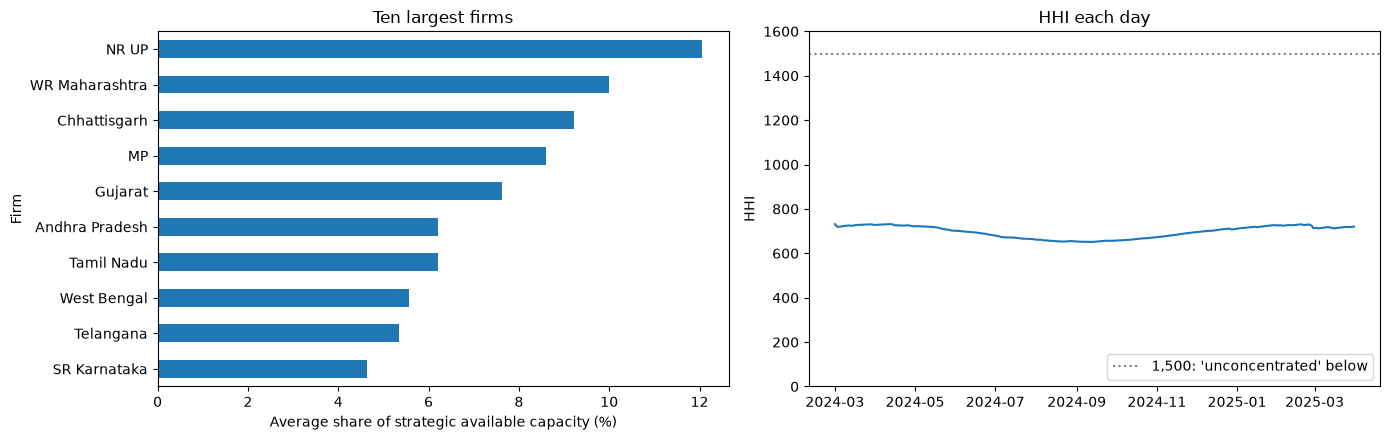

Firm
NR UP             12.0
WR Maharashtra    10.0
Chhattisgarh       9.2
MP                 8.6
Gujarat            7.6
Andhra Pradesh     6.2
Tamil Nadu         6.2
West Bengal        5.6
Telangana          5.3
SR Karnataka       4.6
Name: Average share %, dtype: float64

In [3]:
share = shares(firm_mw)
hhi_daily = hhi(share)
assert (share.sum(axis=1) - 1).abs().max() < 1e-9          # shares add up to 100% every day

installed = shares(strategic.groupby("Firm")["Capacity_MW"].sum().to_frame().T)
print(f"HHI on installed strategic capacity: {hhi(installed).iloc[0]:,.0f}")
print(f"HHI on daily available capacity: mean {hhi_daily.mean():,.0f}, "
      f"range {hhi_daily.min():,.0f}–{hhi_daily.max():,.0f}")

top10 = share.mean().sort_values(ascending=False).head(10)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(top10 * 100).iloc[::-1].plot(kind="barh", ax=ax[0], color="tab:blue")
ax[0].set_xlabel("Average share of strategic available capacity (%)")
ax[0].set_title("Ten largest firms")
ax[1].plot(hhi_daily.index, hhi_daily, color="tab:blue")
ax[1].axhline(1500, color="tab:gray", linestyle=":", label="1,500: 'unconcentrated' below")
ax[1].set_ylim(0, 1600)
ax[1].set_ylabel("HHI")
ax[1].set_title("HHI each day")
ax[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

(top10 * 100).round(1).rename("Average share %")

**Regions (descriptive only).** With no transmission limits there is one national market; these figures say who would dominate a region *if* a corridor filled up and split the market (Stage 7).

In [4]:
region_mw = firm_mw.T.groupby(lambda f: REGIONS[f])
rows = []
for region, mw in region_mw:
    s = shares(mw.T)
    biggest = s.mean().idxmax()
    rows.append({"Region": region, "Firms": mw.shape[0],
                 "Strategic GW (avg)": mw.sum().mean() / 1000,
                 "Largest firm": biggest, "Its share %": 100 * s.mean().max(),
                 "Regional HHI (avg)": hhi(s).mean()})
pd.DataFrame(rows).set_index("Region").round(1)

,Firms,Strategic GW (avg),Largest firm,Its share %,Regional HHI (avg)
Region,,,,,
East,4,28.0,West Bengal,39.3,3218.5
North,8,51.7,NR UP,46.1,2712.7
NorthEast,7,2.5,Assam,39.5,3226.3
South,6,45.3,Andhra Pradesh,27.1,2436.3
West,5,69.9,WR Maharashtra,28.2,2525.3


### 1.2 Residual Supply Index and pivotal firms

RSI = (all available MW − firm's strategic MW) ÷ (demand + losses). RSI < 1: the market can't be served without the firm.

In [5]:
r = rsi(total, firm_mw, need)
lowest = r.min(axis=1)
joint2 = joint_rsi(total, firm_mw, need, 2)
joint3 = joint_rsi(total, firm_mw, need, 3)

single = r < 1
near = r < 1.1
tests = pd.DataFrame({
    "Single pivotal (RSI < 1)": single.any(axis=1),
    "Near-pivotal (RSI < 1.1)": near.any(axis=1),
    "2 largest jointly (RSI < 1)": joint2 < 1,
    "3 largest jointly (RSI < 1)": joint3 < 1,
})
assert (r >= 0).all().all()

summary = pd.DataFrame({"Days": tests.sum(), "% of 396": (100 * tests.mean()).round(1)})
summary

,Days,% of 396
Single pivotal (RSI < 1),53,13.4
Near-pivotal (RSI < 1.1),219,55.3
2 largest jointly (RSI < 1),201,50.8
3 largest jointly (RSI < 1),312,78.8


In [6]:
# Cross-check with the plan's preview (53 days, UP on all 53) and the effect of decisions 1 and 2
all_mw = firm_supply(blocks, available, roles=("strategic", "must-run", "cost")).loc[DAYS]
demand_only = m0["Demand_MW"].loc[DAYS]
check = {}
for firms, mw in [("strategic only", firm_mw), ("all blocks", all_mw)]:
    for req_name, req in [("demand + losses", need), ("demand only", demand_only)]:
        p = rsi(total, mw, req) < 1
        check[(firms, req_name)] = {"Days with a pivotal firm": int(p.any(axis=1).sum()),
                                    "Firms ever pivotal": int((p.sum() > 0).sum()),
                                    "Most often pivotal": p.sum().idxmax()}
check = pd.DataFrame(check).T
assert check.loc[("strategic only", "demand + losses"), "Days with a pivotal firm"] == 53
assert single["NR UP"].sum() == 53
check

Days with a pivotal firm Firms ever pivotal  \
strategic only demand + losses                       53                  9   
               demand only                           39                  8   
all blocks     demand + losses                      116                 11   
               demand only                          103                 11   

                               Most often pivotal  
strategic only demand + losses              NR UP  
               demand only                  NR UP  
all blocks     demand + losses            Gujarat  
               demand only                Gujarat

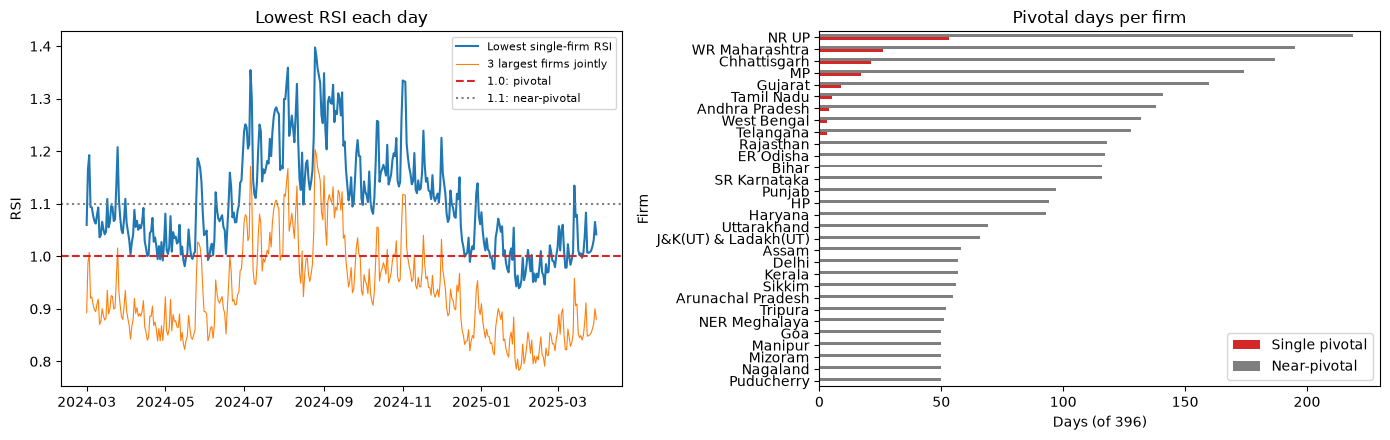

,Single pivotal,Near-pivotal
Firm,,
NR UP,53,219
WR Maharashtra,26,195
Chhattisgarh,21,187
MP,17,174
Gujarat,9,160
Tamil Nadu,5,141
Andhra Pradesh,4,138
West Bengal,3,132
Telangana,3,128


In [7]:
per_firm = pd.DataFrame({"Single pivotal": single.sum(), "Near-pivotal": near.sum()})
per_firm = per_firm[per_firm.sum(axis=1) > 0].sort_values(["Single pivotal", "Near-pivotal"], ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(lowest.index, lowest, color="tab:blue", label="Lowest single-firm RSI")
ax[0].plot(joint3.index, joint3, color="tab:orange", linewidth=0.8, label="3 largest firms jointly")
ax[0].axhline(1.0, color="tab:red", linestyle="--", label="1.0: pivotal")
ax[0].axhline(1.1, color="tab:gray", linestyle=":", label="1.1: near-pivotal")
ax[0].set_ylabel("RSI")
ax[0].set_title("Lowest RSI each day")
ax[0].legend(loc="upper right", fontsize=8)
per_firm.iloc[::-1].plot(kind="barh", ax=ax[1], color=["tab:red", "tab:gray"])
ax[1].set_xlabel("Days (of 396)")
ax[1].set_title("Pivotal days per firm")
plt.tight_layout()
plt.show()

per_firm

In [8]:
# Caveat for the near-pivotal test: on days when ALL supply is below 1.1 × requirement,
# every firm passes it, even one with no capacity at all. Count those days.
system_ratio = total / need
print(f"Days when total supply < 1.1 × requirement (every firm 'near-pivotal'): {(system_ratio < 1.1).sum()}")
print(f"Days when total supply < requirement (shortage at cost): {(system_ratio < 1).sum()}")
print("Single-pivotal days with 2 or more pivotal firms:", int((single.sum(axis=1) >= 2).sum()), "of", int(single.any(axis=1).sum()))
print(f"Competitive price (demand-weighted, M0): pivotal days {m0.loc[DAYS][single.any(axis=1).values]['Price_avg'].mean():,.0f}, "
      f"other days {m0.loc[DAYS][~single.any(axis=1).values]['Price_avg'].mean():,.0f} Rs/MWh")

Days when total supply < 1.1 × requirement (every firm 'near-pivotal'): 50
Days when total supply < requirement (shortage at cost): 0
Single-pivotal days with 2 or more pivotal firms: 26 of 53
Competitive price (demand-weighted, M0): pivotal days 3,748, other days 3,039 Rs/MWh


### 1.3 When are firms pivotal?

Season, tightness (spare capacity ÷ demand, from Part 2's package) and the near-step flag (the price sits next to a coal-tier step, Part 2).

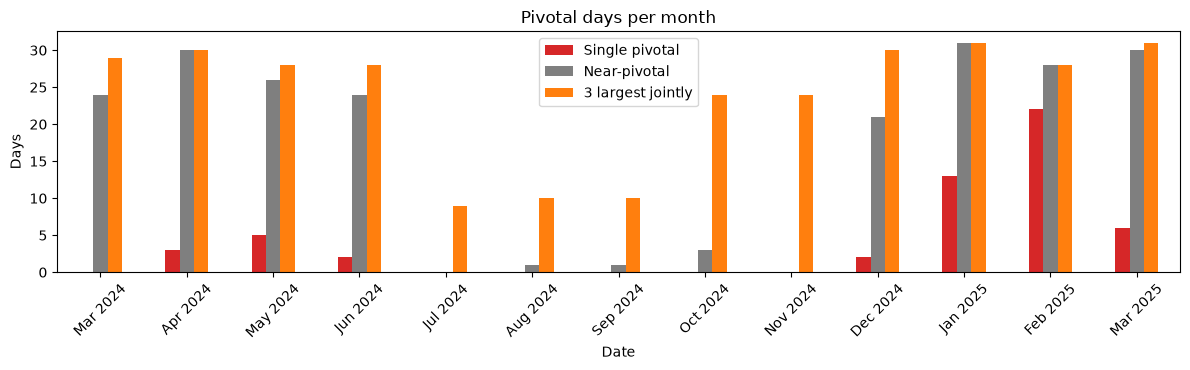

Single-pivotal days  Days  % pivotal
Tightness band Near_step                                      
< 10%          False                       40    40      100.0
               True                         5     5      100.0
10–15%         False                        8    52       15.0
               True                         0    35        0.0
15–20%         False                        0    44        0.0
               True                         0    31        0.0
20–30%         False                        0   108        0.0
               True                         0     3        0.0
≥ 30%          False                        0    70        0.0
               True                         0     8        0.0

In [9]:
pkg = load_forecast_package()
national_pkg = pkg[pkg["Area"] == "National"].set_index("Date").loc[DAYS]

days = pd.DataFrame({
    "Lowest_RSI": lowest, "Single": tests["Single pivotal (RSI < 1)"],
    "Near": tests["Near-pivotal (RSI < 1.1)"], "Joint3": tests["3 largest jointly (RSI < 1)"],
    "Tightness": national_pkg["Tightness_actual"], "Near_step": national_pkg["Near_step_actual"].astype(bool),
})

# By month
by_month = days.groupby(days.index.to_period("M"))[["Single", "Near", "Joint3"]].sum()
by_month.index = by_month.index.strftime("%b %Y")
by_month.plot(kind="bar", figsize=(12, 3.8), rot=45, color=["tab:red", "tab:gray", "tab:orange"],
              title="Pivotal days per month", ylabel="Days")
plt.legend(["Single pivotal", "Near-pivotal", "3 largest jointly"])
plt.tight_layout()
plt.show()

# Tightness and near-step (hypothesis 4)
days["Tightness band"] = pd.cut(days["Tightness"], [-1, 0.10, 0.15, 0.20, 0.30, 10],
                                labels=["< 10%", "10–15%", "15–20%", "20–30%", "≥ 30%"])
table = days.groupby(["Tightness band", "Near_step"], observed=False)["Single"].agg(["sum", "count"])
table.columns = ["Single-pivotal days", "Days"]
table["% pivotal"] = (100 * table["Single-pivotal days"] / table["Days"]).round(0)
table

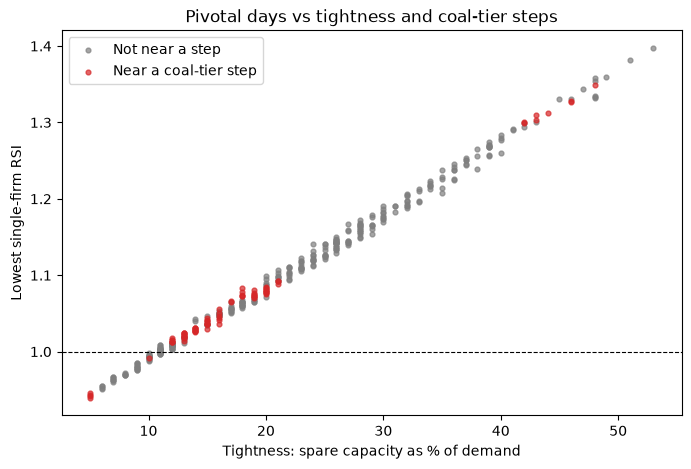

Correlation of lowest RSI with tightness: 0.998
Share of single-pivotal days that are near a step: 9% (all days: 21%)


In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
for flag, color, label in [(False, "tab:gray", "Not near a step"), (True, "tab:red", "Near a coal-tier step")]:
    d = days[days["Near_step"] == flag]
    ax.scatter(100 * d["Tightness"], d["Lowest_RSI"], s=12, color=color, alpha=0.7, label=label)
ax.axhline(1.0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlabel("Tightness: spare capacity as % of demand")
ax.set_ylabel("Lowest single-firm RSI")
ax.set_title("Pivotal days vs tightness and coal-tier steps")
ax.legend()
plt.show()

print("Correlation of lowest RSI with tightness:", round(days["Lowest_RSI"].corr(days["Tightness"]), 3))
print("Share of single-pivotal days that are near a step:",
      f"{100 * days.loc[days['Single'], 'Near_step'].mean():.0f}%",
      f"(all days: {100 * days['Near_step'].mean():.0f}%)")

## Stage 1 conclusions

| # | Hypothesis | Result |
|---|---|---|
| 1 | HHI below 1,500, yet firms pivotal | ✅ **HHI 696 on average** (range 651–732; installed 645): "unconcentrated" by the usual bands, yet **53 days** have a pivotal firm. Concentration ≠ market power |
| 2 | Reproduce the plan's preview | ✅ **53 days, UP pivotal on all 53**, 9 firms ever pivotal: exactly the preview |
| 3 | Pivotal days cluster in summer 2024 | ❌ Mostly **winter: Jan–Feb 2025 has 35 of the 53 days** (summer 2024: 10). Low wind and hydro in winter (the seasonal pattern found in notebook 04, model log Step 10) plus demand growth beat the summer peak |
| 4 | Pivotal days are tight **and** near a coal-tier step | ❌ Tight yes (all 53 have **5–11% spare**), but **only 9% are near a step** (all days: 21%). On pivotal days the price is already high (Rs 3,748 vs 3,039 on other days), above the coal steps |
| 5 | Jointly > near-pivotal > single | ⚠️ Partly: 3 largest jointly **312** days > near-pivotal **219** > 2 largest jointly **201** > single **53** |

**Main findings**
- **Market power is a tightness story.** The lowest RSI and tightness are almost the same measure (correlation 0.998): every day under ~10% spare has a pivotal firm, no day above 11% does.
- **Pivotal firms are the big central and western coal states:** UP (53 days), Maharashtra (26), Chhattisgarh (21), MP (17), Gujarat (9); then Tamil Nadu, Andhra Pradesh, West Bengal, Telangana (3–5 each).
- **Rivals are often pivotal together:** on 26 of the 53 days two or more firms are pivotal (up to 9). Whether they limit each other is Stage 5's question.
- **Two different kinds of risky day:** pivotal days (very tight, price near the top) where a firm could push towards the cap; near-step days (10–20% spare) where a small withholding could jump the price one coal tier. Stage 3 tests both.
- **Regions (descriptive only):** each region is concentrated (HHI 2,400–3,200); UP holds 46% of the North's strategic capacity. Matters only if a transmission limit splits the market (Stage 7).

**Caveat:** the near-pivotal test (RSI < 1.1) is weak on very tight days: on **50 days** total supply is below 1.1 × requirement, so every firm passes it, even the smallest. That is why tiny firms (Mizoram, Puducherry) show ~50 near-pivotal days. Per-firm near-pivotal counts are only meaningful for large firms.

### Save

In [11]:
long = (firm_mw.stack().rename("Strategic_MW").to_frame()
        .join(share.stack().rename("Share"))
        .join(r.stack().rename("RSI")))
long["Pivotal"] = long["RSI"] < 1
long["Near_pivotal"] = long["RSI"] < 1.1
long["Region"] = [REGIONS[f] for f in long.index.get_level_values("Firm")]
long.reset_index().to_csv("../data/processed/market_structure_daily.csv", index=False)

national = pd.DataFrame({
    "Total_available_MW": total, "Requirement_MW": need, "HHI": hhi_daily,
    "Lowest_RSI": lowest, "Lowest_RSI_firm": r.idxmin(axis=1),
    "Pivotal_firms": single.sum(axis=1), "Near_pivotal_firms": near.sum(axis=1),
    "Joint2_RSI": joint2, "Joint3_RSI": joint3,
    "Tightness": days["Tightness"], "Near_step": days["Near_step"],
})
national.index.name = "Date"
national.reset_index().to_csv("../data/processed/market_structure_national_daily.csv", index=False)
print(f"market_structure_daily.csv: {len(long):,} rows; market_structure_national_daily.csv: {len(national)} rows")

market_structure_daily.csv: 11,880 rows; market_structure_national_daily.csv: 396 rows


## Stage 2 — Bids inside the LP

Every block now has **two prices**: its **bid** (what the market sees: dispatch runs cheapest bid first) and its **true cost** (what it really costs: used for profit). Profit per MW = clearing price − true cost.

| Tool | Where | What it does |
|---|---|---|
| `solve(..., costs=)` | `src/dispatch.py` | Bids for this day only; same keys as `availability` (fuel or (state, fuel)); blocks not given bid their true cost; every bid must be below VOLL |
| `make_bids(blocks, adders)` | `src/bidding.py` | A firm's strategic blocks bid **cost + adder + 1** (adder > 0), capped at **Rs 8,990** |
| `make_availability(base, blocks, withholding)` | `src/bidding.py` | A firm's strategic availability × (1 − share); must-run and cost blocks never change |
| `firm_profit`, `consumer_cost`, `generation_cost` | `src/bidding.py` | Profit at true cost (incl. the firm's solar and wind); Σ price × demand; true cost of what ran |

**Decisions (Step 23):**
1. **Highest bid Rs 8,990.** VOLL is also the price cap (Rs 10,000). A bid at the cap ties with leaving demand unserved; and because of **losses**, power bid at b costs up to b ÷ 0.9 where it lands (10% is the longest route's loss). A first try with a cap of Rs 9,990 left **14,390 MW unserved** when UP bid the cap on 30 Jan 2025: for distant states a blackout at Rs 10,000 was "cheaper" than imports at 9,990 ÷ 0.97. So the highest bid is 10,000 × 0.9 − 10 = **8,990**: delivered power always stays below Rs 10,000, every state is served while supply exists, and no state's price goes above the cap
2. **Raised bids get +Rs 1** (cost + adder + 1). Costs are round hundreds and adders steps of 250, so 6 combinations would otherwise land exactly on another block's cost (e.g. lignite 2,300 + 500 = 2,800 = inland coal), making dispatch arbitrary

### Check 1 — the plan's hand example

Firm A owns 80 MW at Rs 1,000; the rest of the market is 50 MW at Rs 2,000 bidding cost; demand 100 MW. The rest can't cover demand alone, so A is pivotal. By hand: bidding below 2,000 earns (2,000 − 1,000) × 80 = **80,000**; bidding the cap earns (8,990 − 1,000) × 50 = **399,500**.

In [12]:
import numpy as np
from dispatch import LossDispatchModel, load_demand, load_coordinates, loss_matrix, daily_availability_lookup, VOLL
from bidding import make_bids, make_availability, firm_profit, consumer_cost, generation_cost, MAX_BID

hand_gen = pd.DataFrame({"State": ["A", "B"], "Fuel_Type": ["Coal", "Nuclear"],
                         "Capacity_MW": [80.0, 50.0], "Marginal_Cost_Rs_per_MWh": [1000.0, 2000.0],
                         "Available_MW": [80.0, 50.0]})
hand_loss = pd.DataFrame([[np.nan, 0.0], [0.0, np.nan]], index=["A", "B"], columns=["A", "B"])
hand_model = LossDispatchModel(hand_gen, hand_loss, ["A", "B"])
hand_blocks = firm_blocks(hand_gen)
hand_demand = pd.Series({"A": 100.0, "B": 0.0})

rows = []
for adder in [0, 500, 998, 1000, 2500, 5000, 8000, 20000]:
    out = hand_model.solve(hand_demand, costs=make_bids(hand_blocks, {"A": adder}))
    g = out["generation"].set_index("State")
    rows.append({"Adder": adder, "A's bid": g.loc["A", "Bid"], "Price": out["states"].loc["A", "Price"],
                 "A sells MW": g.loc["A", "Dispatch_MW"], "A's profit": firm_profit(out, hand_blocks)["A"],
                 "Consumers pay": consumer_cost(out)})
sweep = pd.DataFrame(rows).set_index("Adder")
assert sweep.loc[500, "A's profit"] == 80_000 and sweep.loc[20000, "A's profit"] == 399_500
sweep.round(0)

,A's bid,Price,A sells MW,A's profit,Consumers pay
Adder,,,,,
0,1000.0,2000.0,80.0,80000.0,200000.0
500,1501.0,2000.0,80.0,80000.0,200000.0
998,1999.0,2000.0,80.0,80000.0,200000.0
1000,2001.0,2001.0,50.0,50050.0,200100.0
2500,3501.0,3501.0,50.0,125050.0,350100.0
5000,6001.0,6001.0,50.0,250050.0,600100.0
8000,8990.0,8990.0,50.0,399500.0,899000.0
20000,8990.0,8990.0,50.0,399500.0,899000.0


Up to a bid of Rs 2,000, A sells all 80 MW at the fringe's price (profit 80,000). Once A bids **above** the fringe (adder 1,000 → bid 2,001), the fringe runs first and **A becomes the price-setter**: it sells only the 50 MW the fringe can't cover, but every MW earns its own bid. Profit rises in a straight line with the bid, all the way to the cap: **a pivotal firm's best bid is the cap**. Consumers pay up to 4.5 times more for the same 100 MW.

### Check 2 — bidding true cost reproduces the competitive run

Real stack, Part 2's weather-based availability. If every block bids its true cost through `costs=`, prices must equal the saved competitive run (`dispatch_weather_state_daily.csv`) exactly. Days: the national peak (30 May 2024), Part 1's reference day (21 Jul 2024) and a pivotal winter day (10 Feb 2025).

In [13]:
demand = load_demand()
states = list(demand.columns)
model = LossDispatchModel(gen, loss_matrix(load_coordinates(), states), states)
lookup = daily_availability_lookup(daily[daily["Date"].isin(DAYS)])
saved = pd.read_csv("../data/processed/dispatch_weather_state_daily.csv", parse_dates=["Date"])

true_costs = {(s, f): c for s, f, c in zip(gen["State"], gen["Fuel_Type"], gen["Marginal_Cost_Rs_per_MWh"])
              if c < VOLL}    # diesel (Rs 11,000) is left at its cost: above the cap, it never runs
for date in ["2024-05-30", "2024-07-21", "2025-02-10"]:
    d = pd.Timestamp(date)
    out = model.solve(demand.loc[d], lookup[d], costs=true_costs)
    ref = saved[saved["Date"] == d].set_index("State")["Price"]
    diff = (out["states"]["Price"].reindex(ref.index) - ref).abs().max()
    print(f"{date}: largest price difference vs saved run = {diff:.2e} Rs/MWh")
    assert diff < 1e-6

2024-05-30: largest price difference vs saved run = 0.00e+00 Rs/MWh
2024-07-21: largest price difference vs saved run = 0.00e+00 Rs/MWh
2025-02-10: largest price difference vs saved run = 0.00e+00 Rs/MWh


### First look on real data (Stage 3 searches properly)

UP on its tightest pivotal day: what happens if it raises its strategic bids, or withholds some of its strategic capacity? A handful of strategies only, to see the tools work on the real stack. (This is the case that exposed the blackout problem with a Rs 9,990 cap; now unserved stays 0.)

In [14]:
tightest = r["NR UP"].idxmin()
print(f"UP's tightest day: {tightest.date()}, RSI {r.loc[tightest, 'NR UP']:.3f}, "
      f"spare capacity {100 * days.loc[tightest, 'Tightness']:.1f}%")

base_avail = lookup[tightest]
base = model.solve(demand.loc[tightest], base_avail)
base_profit = firm_profit(base, blocks)["NR UP"]
base_cost = consumer_cost(base)

rows = []
for adder, w in [(0, 0), (500, 0), (2000, 0), (20000, 0), (0, 0.1), (0, 0.3)]:
    out = model.solve(demand.loc[tightest], make_availability(base_avail, blocks, {"NR UP": w}),
                      costs=make_bids(blocks, {"NR UP": adder}))
    st = out["states"]
    rows.append({"Adder": adder, "Withhold": f"{w:.0%}",
                 "UP price": st.loc["NR UP", "Price"],
                 "Avg price": np.average(st["Price"], weights=st["Demand_MW"]),
                 "UP profit (Rs lakh/h)": firm_profit(out, blocks)["NR UP"] / 1e5,
                 "Consumer cost change %": 100 * (consumer_cost(out) / base_cost - 1),
                 "Unserved MW": st["Unserved_MW"].sum()})
pd.DataFrame(rows).round(1)

UP's tightest day: 2025-01-30, RSI 0.939, spare capacity 5.0%


,Adder,Withhold,UP price,Avg price,UP profit (Rs lakh/h),Consumer cost change %,Unserved MW
0,0,0%,3722.4,3766.4,411.3,0.0,0.0
1,500,0%,3722.4,3766.4,411.3,0.0,0.0
2,2000,0%,4201.0,4231.4,481.7,12.3,0.0
3,20000,0%,8990.0,9015.7,1208.5,139.4,0.0
4,0,10%,3790.0,3824.0,391.9,1.5,0.0
5,0,30%,4540.3,4553.6,461.9,20.9,0.0
